# Chương 7 (Chặng 2): Dự báo Doanh thu Chuỗi thời gian bằng PyTorch LSTM & GRU (Google Colab GPU)

**Mục tiêu thực nghiệm:**
- Huấn luyện hai kiến trúc Mạng Nơ-ron Hồi quy Sâu (**LSTM** và **GRU**) bằng **PyTorch** trên đúng tập dữ liệu chuỗi thời gian doanh thu ngày (`593 ngày`: **533 ngày Train** `2017-01-05 -> 2018-06-21` và **60 ngày Hold-out Test** `2018-06-22 -> 2018-08-20`) đã xuất từ Chặng 1 (`ts_daily_revenue_for_colab.csv`).
- Đảm bảo **Kỷ luật Chống Rò rỉ Dữ liệu (Zero Data Leakage)**: chỉ `fit` bộ chuẩn hóa trên tập `train`, tách 60 ngày cuối của `train` làm `validation` cho **Early Stopping**, và dự báo đa bước đệ quy (**60-step Recursive Forecast**) chỉ sử dụng các đặc trưng lịch hoàn toàn biết trước trong tương lai.
- Xuất file `colab_dl_forecasts.csv` về máy cục bộ (`data/processed/colab_dl_forecasts.csv`) để chạy `python -m src.models.compare_forecast_models` đối chiếu công bằng 4 mô hình: **Seasonal Naive vs SARIMAX vs LSTM vs GRU**.

## Cell 1 — Thiết lập Môi trường, Kiểm tra GPU & Khóa Seed Tái lập (`SEED = 42`)

In [1]:
import copy
import os
import random
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42

def set_all_seeds(seed: int = 42) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_all_seeds(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch version : {torch.__version__}')
print(f'Compute device  : {device}')
if device.type == 'cuda':
    print(f'GPU Name        : {torch.cuda.get_device_name(0)}')

PyTorch version : 2.14.1+cpu
Compute device  : cpu


## Cell 2 — Nạp Dữ liệu `ts_daily_revenue_for_colab.csv`
- Nếu chạy trên **Google Colab** và chưa có file trong thư mục hiện tại, hộp thoại upload sẽ tự động bật lên để bạn chọn file `data/processed/ts_daily_revenue_for_colab.csv` từ máy tính.
- Nếu chạy cục bộ ngoài Colab, code tự động đọc từ `../data/processed/ts_daily_revenue_for_colab.csv`.

In [2]:
CSV_NAME = 'ts_daily_revenue_for_colab.csv'
local_candidates = [
    Path(CSV_NAME),
    Path('../data/processed') / CSV_NAME,
    Path('data/processed') / CSV_NAME,
]

csv_path = next((p for p in local_candidates if p.is_file()), None)

if csv_path is None:
    try:
        from google.colab import files  # type: ignore
        print('Vui lòng chọn file ts_daily_revenue_for_colab.csv từ thư mục data/processed/ trên máy của bạn:')
        uploaded = files.upload()
        csv_path = Path(next(iter(uploaded.keys())))
    except ImportError as exc:
        raise FileNotFoundError(
            'Không tìm thấy ts_daily_revenue_for_colab.csv. Hãy chạy python -m src.models.forecast_sarimax trước!'
        ) from exc

df = pd.read_csv(csv_path)
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

n_total = len(df)
n_train = int((df['split'] == 'train').sum())
n_test = int((df['split'] == 'test').sum())
assert n_total == 593 and n_train == 533 and n_test == 60, (
    f'Sai lệch kích thước tập dữ liệu: total={n_total}, train={n_train}, test={n_test}'
)

print(f'Đã nạp thành công: {csv_path} ({n_total} ngày)')
print(f"- Tập Train : {n_train} ngày ({df.loc[df['split']=='train', 'date'].min().date()} -> {df.loc[df['split']=='train', 'date'].max().date()})")
print(f"- Tập Test  : {n_test} ngày ({df.loc[df['split']=='test', 'date'].min().date()} -> {df.loc[df['split']=='test', 'date'].max().date()})")
df.head(3)

Vui lòng chọn file ts_daily_revenue_for_colab.csv từ thư mục data/processed/ trên máy của bạn:


Saving ts_daily_revenue_for_colab.csv to ts_daily_revenue_for_colab.csv
Đã nạp thành công: ts_daily_revenue_for_colab.csv (593 ngày)
- Tập Train : 533 ngày (2017-01-05 -> 2018-06-21)
- Tập Test  : 60 ngày (2018-06-22 -> 2018-08-20)


,date,daily_orders,daily_gmv,is_weekend,is_black_friday,is_black_friday_weekend,is_early_month,split
0,2017-01-05,32,707.27,0,0,0,1,train
1,2017-01-06,4,988.28,0,0,0,1,train
2,2017-01-07,4,1447.99,1,0,0,1,train


## Cell 3 — Feature Engineering Chu kỳ Lịch & Chuẩn hóa Chống Rò rỉ (No Data Leakage)
- **Đặc trưng chu kỳ lượng giác (`sin`/`cos`):** Giúp mạng nơ-ron hiểu Chủ nhật (`dayofweek=6`) nằm sát cạnh Thứ Hai (`dayofweek=0`), và cuối tháng nằm sát đầu tháng.
- **Biến đổi mục tiêu `np.log1p(daily_gmv)`:** Ổn định phương sai giống SARIMAX ở Chặng 1 và đảm bảo dự báo sau `expm1` không bao giờ âm.
- **Chống Data Leakage:** `StandardScaler` chỉ được `fit()` duy nhất trên `533` ngày `train`, tuyệt đối không nhìn thấy `60` ngày `test`. Đồng thời tách **60 ngày cuối của `train`** làm tập `validation` phục vụ Early Stopping.

In [3]:
dow = df['date'].dt.dayofweek.astype(float)
dom = df['date'].dt.day.astype(float)

df['dow_sin'] = np.sin(2.0 * np.pi * dow / 7.0)
df['dow_cos'] = np.cos(2.0 * np.pi * dow / 7.0)
df['dom_sin'] = np.sin(2.0 * np.pi * (dom - 1.0) / 31.0)
df['dom_cos'] = np.cos(2.0 * np.pi * (dom - 1.0) / 31.0)

CALENDAR_COLS = [
    'dow_sin', 'dow_cos', 'dom_sin', 'dom_cos',
    'is_weekend', 'is_black_friday', 'is_black_friday_weekend', 'is_early_month',
]

df['y_log'] = np.log1p(df['daily_gmv'].astype(float))

train_mask = df['split'] == 'train'
scaler_y = StandardScaler()
scaler_y.fit(df.loc[train_mask, ['y_log']])
df['y_scaled'] = scaler_y.transform(df[['y_log']]).ravel()

LOOKBACK = 21  # Cửa sổ trượt 21 ngày (3 chu kỳ tuần hoàn chỉnh)
VAL_SIZE = 60  # 60 ngày cuối của tập Train dùng cho Validation / Early Stopping
TRAIN_END_IDX = n_train          # 533
SUBTRAIN_END_IDX = n_train - VAL_SIZE  # 473

def build_supervised_windows(frame: pd.DataFrame, start_target_idx: int, end_target_idx: int):
    X_seq_list, X_fut_cal_list, y_target_list = [], [], []
    cal_arr = frame[CALENDAR_COLS].to_numpy(dtype=np.float32)
    y_arr = frame['y_scaled'].to_numpy(dtype=np.float32)
    for t in range(start_target_idx, end_target_idx):
        past_y = y_arr[t - LOOKBACK : t].reshape(-1, 1)
        past_cal = cal_arr[t - LOOKBACK : t]
        seq_x = np.hstack([past_y, past_cal])  # (LOOKBACK, 1 + 8)
        X_seq_list.append(seq_x)
        X_fut_cal_list.append(cal_arr[t])      # Đặc trưng lịch biết trước của ngày mục tiêu t
        y_target_list.append(y_arr[t])
    return (
        torch.tensor(np.array(X_seq_list), dtype=torch.float32),
        torch.tensor(np.array(X_fut_cal_list), dtype=torch.float32),
        torch.tensor(np.array(y_target_list), dtype=torch.float32).unsqueeze(1),
    )

X_seq_tr, X_cal_tr, y_tr = build_supervised_windows(df, LOOKBACK, SUBTRAIN_END_IDX)
X_seq_val, X_cal_val, y_val = build_supervised_windows(df, SUBTRAIN_END_IDX, TRAIN_END_IDX)

print(f'Sub-train windows : {X_seq_tr.shape} | Target cal: {X_cal_tr.shape}')
print(f'Validation windows: {X_seq_val.shape} | Target cal: {X_cal_val.shape}')

Sub-train windows : torch.Size([452, 21, 9]) | Target cal: torch.Size([452, 8])
Validation windows: torch.Size([60, 21, 9]) | Target cal: torch.Size([60, 8])


## Cell 4 — Kiến trúc PyTorch `LSTMForecaster` & `GRUForecaster` và Quá trình Huấn luyện
- Cả hai mô hình dùng chung cấu hình công bằng: `hidden_size = 48`, `num_layers = 2`, `dropout = 0.2`.
- Trạng thái ẩn cuối cùng của chuỗi quá khứ `21 ngày` được ghép (`concat`) với vector đặc trưng lịch của **ngày mục tiêu `t`** trước khi đi qua tầng `Linear` đầu ra — giúp dự báo đa bước 60 ngày giữ nhịp mùa vụ tuần chính xác.
- Tối ưu bằng `AdamW` (`lr=1e-3`, `weight_decay=1e-4`), hàm mất mát **`HuberLoss`** (bền vững trước đỉnh nhọn Black Friday), `clip_grad_norm_ = 1.0`, `ReduceLROnPlateau` và **Early Stopping**.

In [4]:
class RecurrentForecaster(nn.Module):
    def __init__(
        self,
        rnn_type: str,
        seq_input_dim: int,
        cal_dim: int,
        hidden_size: int = 48,
        num_layers: int = 2,
        dropout: float = 0.2,
    ) -> None:
        super().__init__()
        rnn_cls = nn.LSTM if rnn_type.upper() == 'LSTM' else nn.GRU
        self.rnn = rnn_cls(
            input_size=seq_input_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.Linear(hidden_size + cal_dim, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def forward(self, x_seq: torch.Tensor, x_fut_cal: torch.Tensor) -> torch.Tensor:
        rnn_out, _ = self.rnn(x_seq)
        last_hidden = rnn_out[:, -1, :]
        combined = torch.cat([last_hidden, x_fut_cal], dim=1)
        return self.head(combined)


def train_recurrent_model(
    rnn_type: str,
    max_epochs: int = 180,
    batch_size: int = 32,
    patience: int = 25,
):
    set_all_seeds(SEED)
    model = RecurrentForecaster(
        rnn_type=rnn_type,
        seq_input_dim=X_seq_tr.shape[2],
        cal_dim=X_cal_tr.shape[1],
        hidden_size=48,
        num_layers=2,
        dropout=0.2,
    ).to(device)

    train_loader = DataLoader(
        TensorDataset(X_seq_tr, X_cal_tr, y_tr),
        batch_size=batch_size,
        shuffle=True,
    )
    criterion = nn.HuberLoss(delta=1.0)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=8
    )

    best_val_loss = float('inf')
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    wait = 0
    history = {'train_loss': [], 'val_loss': []}

    for epoch in range(1, max_epochs + 1):
        model.train()
        batch_losses = []
        for b_seq, b_cal, b_y in train_loader:
            b_seq, b_cal, b_y = b_seq.to(device), b_cal.to(device), b_y.to(device)
            optimizer.zero_grad()
            preds = model(b_seq, b_cal)
            loss = criterion(preds, b_y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            batch_losses.append(loss.item())

        tr_loss = float(np.mean(batch_losses))

        model.eval()
        with torch.no_grad():
            val_preds = model(X_seq_val.to(device), X_cal_val.to(device))
            val_loss = float(criterion(val_preds, y_val.to(device)).item())

        scheduler.step(val_loss)
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(val_loss)

        if val_loss < best_val_loss - 1e-5:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'[{rnn_type}] Tham số: {n_params:,} | Hội tụ tại epoch {best_epoch} | Best Val HuberLoss = {best_val_loss:.4f}')
    return model, history

lstm_model, lstm_hist = train_recurrent_model('LSTM')
gru_model, gru_hist = train_recurrent_model('GRU')

[LSTM] Tham số: 32,001 | Hội tụ tại epoch 38 | Best Val HuberLoss = 0.0411
[GRU] Tham số: 24,465 | Hội tụ tại epoch 61 | Best Val HuberLoss = 0.0420


## Cell 5 — Dự báo Đa bước Đệ quy 60 ngày Test (Multi-step Recursive Forecast) & Đánh giá
- Khởi tạo cửa sổ trượt bằng `21 ngày cuối cùng của tập Train` (`t = 512..532`).
- Ở mỗi bước trong `60 ngày Test`, mô hình dự đoán `y_scaled` của ngày đó rồi đẩy ngược giá trị dự đoán vào cửa sổ trượt cho ngày kế tiếp (kèm vector đặc trưng lịch đã biết trước của ngày mục tiêu).

=== KẾT QUẢ DỰ BÁO ĐA BƯỚC 60 NGÀY HOLD-OUT TEST ===
       Model         MAE        RMSE  MAPE (%)  SMAPE (%)
PyTorch LSTM 7655.864847 9270.363639 23.146217  21.865114
 PyTorch GRU 7093.608412 8801.064103 22.273203  20.189508


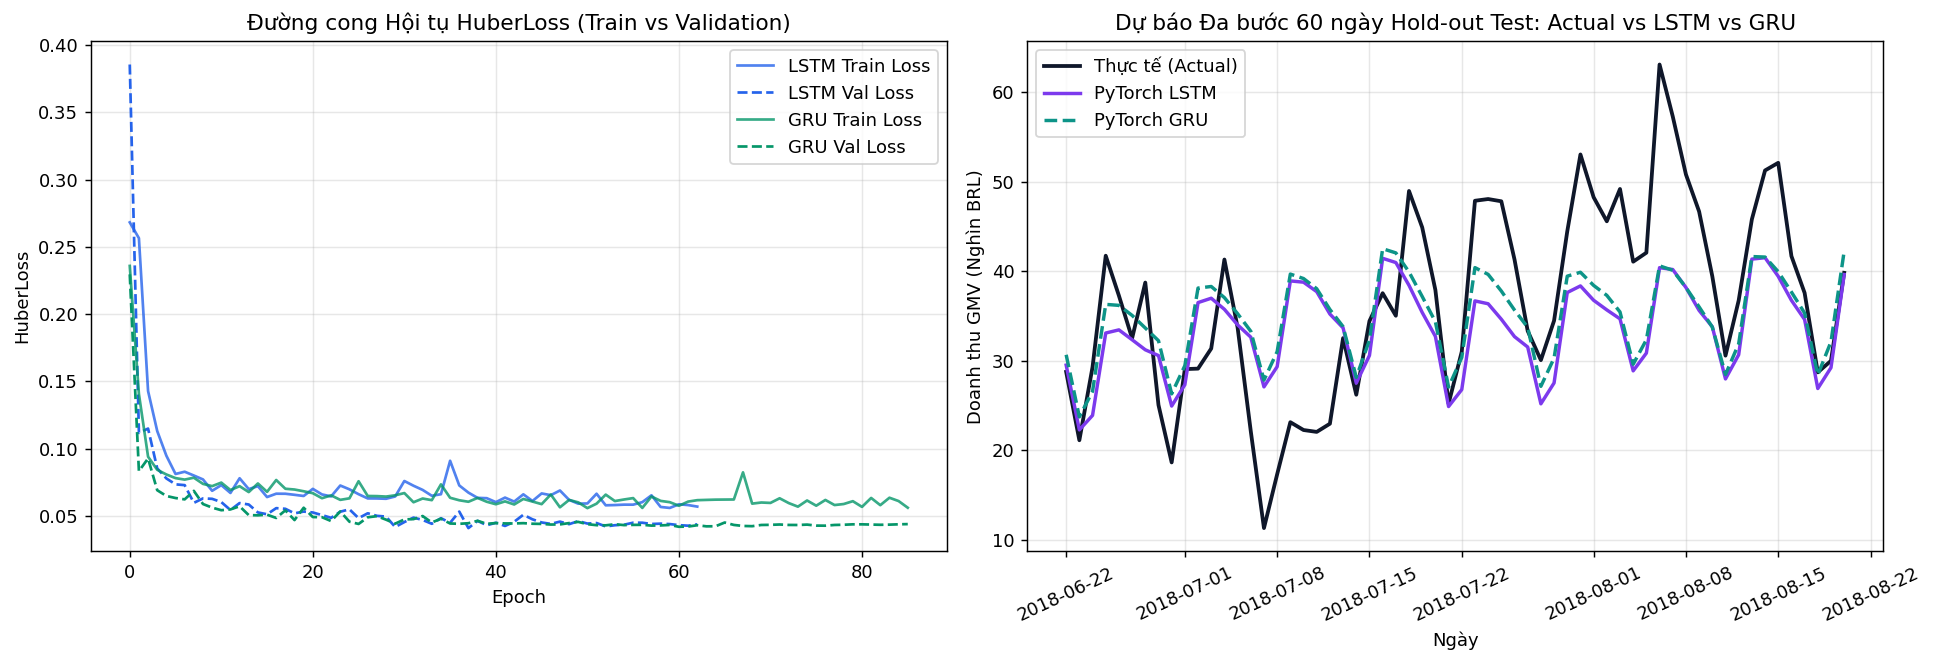

In [5]:
def recursive_forecast_60d(model: nn.Module, frame: pd.DataFrame) -> np.ndarray:
    model.eval()
    cal_arr = frame[CALENDAR_COLS].to_numpy(dtype=np.float32)
    y_hist = list(frame['y_scaled'].iloc[TRAIN_END_IDX - LOOKBACK : TRAIN_END_IDX].to_numpy(dtype=np.float32))
    preds_scaled = []

    with torch.no_grad():
        for step_idx, t in enumerate(range(TRAIN_END_IDX, len(frame))):
            past_y = np.array(y_hist[-LOOKBACK:], dtype=np.float32).reshape(LOOKBACK, 1)
            past_cal = cal_arr[t - LOOKBACK : t]
            seq_x = torch.tensor(np.hstack([past_y, past_cal]), dtype=torch.float32).unsqueeze(0).to(device)
            fut_cal = torch.tensor(cal_arr[t], dtype=torch.float32).unsqueeze(0).to(device)
            pred_s = float(model(seq_x, fut_cal).cpu().item())
            preds_scaled.append(pred_s)
            y_hist.append(pred_s)

    preds_log = scaler_y.inverse_transform(np.array(preds_scaled).reshape(-1, 1)).ravel()
    return np.clip(np.expm1(preds_log), 0.0, None)


def calc_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    mae = float(np.mean(np.abs(y_true - y_pred)))
    rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    mape = float(np.mean(np.abs((y_true - y_pred) / np.maximum(y_true, 1e-8))) * 100.0)
    smape = float(np.mean(2.0 * np.abs(y_pred - y_true) / np.maximum(np.abs(y_true) + np.abs(y_pred), 1e-8)) * 100.0)
    return {'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape, 'SMAPE (%)': smape}

test_df = df.iloc[TRAIN_END_IDX:].copy().reset_index(drop=True)
actual_test = test_df['daily_gmv'].to_numpy(dtype=float)
pred_lstm = recursive_forecast_60d(lstm_model, df)
pred_gru = recursive_forecast_60d(gru_model, df)

metrics_table = pd.DataFrame([
    {'Model': 'PyTorch LSTM', **calc_metrics(actual_test, pred_lstm)},
    {'Model': 'PyTorch GRU', **calc_metrics(actual_test, pred_gru)},
])
print('=== KẾT QUẢ DỰ BÁO ĐA BƯỚC 60 NGÀY HOLD-OUT TEST ===')
print(metrics_table.to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), dpi=130)
ax1.plot(lstm_hist['train_loss'], label='LSTM Train Loss', color='#2563EB', alpha=0.8)
ax1.plot(lstm_hist['val_loss'], label='LSTM Val Loss', color='#2563EB', linestyle='--')
ax1.plot(gru_hist['train_loss'], label='GRU Train Loss', color='#059669', alpha=0.8)
ax1.plot(gru_hist['val_loss'], label='GRU Val Loss', color='#059669', linestyle='--')
ax1.set_title('Đường cong Hội tụ HuberLoss (Train vs Validation)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('HuberLoss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(test_df['date'], actual_test / 1000.0, label='Thực tế (Actual)', color='#0F172A', linewidth=2.1)
ax2.plot(test_df['date'], pred_lstm / 1000.0, label='PyTorch LSTM', color='#7C3AED', linewidth=1.9)
ax2.plot(test_df['date'], pred_gru / 1000.0, label='PyTorch GRU', color='#0D9488', linestyle='--', linewidth=1.9)
ax2.set_title('Dự báo Đa bước 60 ngày Hold-out Test: Actual vs LSTM vs GRU')
ax2.set_xlabel('Ngày')
ax2.set_ylabel('Doanh thu GMV (Nghìn BRL)')
ax2.tick_params(axis='x', rotation=25)
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Cell 6 — Xuất File `colab_dl_forecasts.csv` về Máy Cục bộ
Sau khi tải file `colab_dl_forecasts.csv` về máy, hãy đặt vào thư mục `data/processed/colab_dl_forecasts.csv` và chạy lệnh:
```bash
python -m src.models.compare_forecast_models
```

In [6]:
export_forecasts = pd.DataFrame({
    'date': test_df['date'].dt.strftime('%Y-%m-%d'),
    'actual_gmv': actual_test,
    'pred_lstm': pred_lstm,
    'pred_gru': pred_gru,
})

OUT_CSV = 'colab_dl_forecasts.csv'
export_forecasts.to_csv(OUT_CSV, index=False)
print(f'Đã lưu {OUT_CSV} ({len(export_forecasts)} dòng).')

try:
    from google.colab import files  # type: ignore
    files.download(OUT_CSV)
except ImportError:
    local_dest = Path('../data/processed') / OUT_CSV
    if local_dest.parent.is_dir():
        export_forecasts.to_csv(local_dest, index=False)
        print(f'Đã sao chép trực tiếp vào: {local_dest}')

Đã lưu colab_dl_forecasts.csv (60 dòng).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>